# Long-or-cash backtest

This notebook reads the saved out-of-sample prediction results and daily strategy returns. Each prediction is formed after the current bar closes, then enters at the next bar open and holds through that bar to its close. The backtest applies costs when positions change and closes a position when the next scored timestamp is unavailable, including session ends and data gaps. Cost rates are illustrative all-in transaction-cost and slippage scenarios per side; they are not estimates of a particular broker or execution venue.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
cwd = Path.cwd()
project_root = cwd.parent if cwd.name == 'notebooks' else cwd
results_dir = project_root / 'results'
summary = pd.read_csv(results_dir / 'long_or_cash_backtest_summary.csv')
daily_returns = pd.read_csv(results_dir / 'long_or_cash_backtest_daily_returns.csv', parse_dates=['session_date'])
display(summary.sort_values(['ETF', 'model', 'cost_bps_per_side']).round(4))

,ETF,model,cost_bps_per_side,intervals,active_intervals,exposure_fraction,entries,exits,trade_events,one_way_turnover,entries_per_session,cumulative_cost_fraction_uncompounded,sessions,gross_cumulative_return,net_cumulative_return,maximum_drawdown,annualized_daily_sharpe
5,QQQ,Direction persistence baseline,0.0,23419,11705,0.4998,6139,6139,12278,12278.0,13.2306,0.0000,464,-0.2136,-0.2136,-0.2145,-1.6149
6,QQQ,Direction persistence baseline,1.0,23419,11705,0.4998,6139,6139,12278,12278.0,13.2306,1.2278,464,-0.2136,-0.7697,-0.7697,-9.7285
7,QQQ,Direction persistence baseline,2.5,23419,11705,0.4998,6139,6139,12278,12278.0,13.2306,3.0695,464,-0.2136,-0.9635,-0.9635,-20.5643
8,QQQ,Direction persistence baseline,5.0,23419,11705,0.4998,6139,6139,12278,12278.0,13.2306,6.1390,464,-0.2136,-0.9983,-0.9983,-34.6538
9,QQQ,Direction persistence baseline,10.0,23419,11705,0.4998,6139,6139,12278,12278.0,13.2306,12.2780,464,-0.2136,-1.0000,-1.0000,-51.2486
20,QQQ,LSTM,0.0,23419,16618,0.7096,3771,3771,7542,7542.0,8.1272,0.0000,464,0.1651,0.1651,-0.0656,1.0825
21,QQQ,LSTM,1.0,23419,16618,0.7096,3771,3771,7542,7542.0,8.1272,0.7542,464,0.1651,-0.4520,-0.4525,-4.1235
22,QQQ,LSTM,2.5,23419,16618,0.7096,3771,3771,7542,7542.0,8.1272,1.8855,464,0.1651,-0.8232,-0.8232,-11.9221
23,QQQ,LSTM,5.0,23419,16618,0.7096,3771,3771,7542,7542.0,8.1272,3.7710,464,0.1651,-0.9732,-0.9732,-23.4047
24,QQQ,LSTM,10.0,23419,16618,0.7096,3771,3771,7542,7542.0,8.1272,7.5420,464,0.1651,-0.9994,-0.9994,-37.2451


## How transaction costs change the XGBoost equity curve

This compares the growth of a hypothetical 1 unit invested with no cost and with a 1 bp cost on each side. It makes the cost sensitivity visible across the test period.

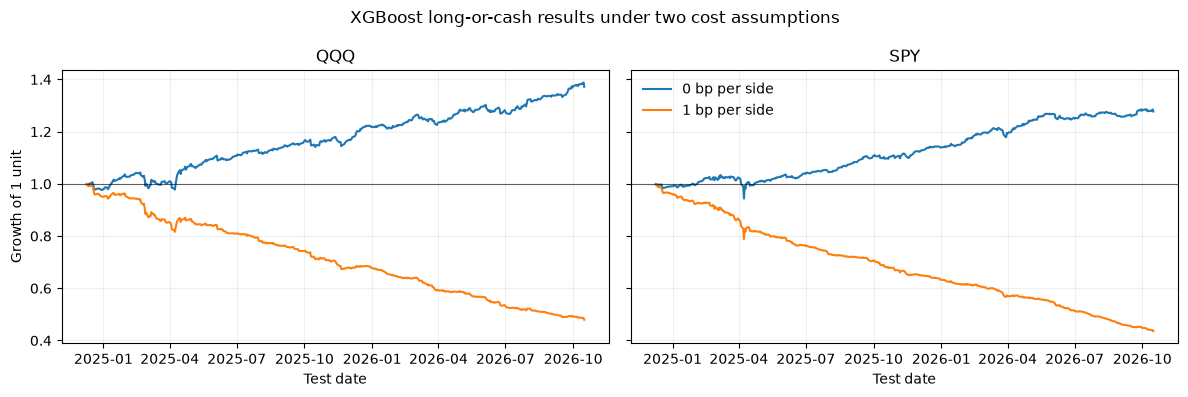

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, ticker in zip(axes, ['QQQ', 'SPY']):
    for cost_bps, color in [(0.0, 'tab:blue'), (1.0, 'tab:orange')]:
        # Each curve starts at 1 and compounds the saved daily net returns.
        series = daily_returns.loc[
            daily_returns['ETF'].eq(ticker)
            & daily_returns['model'].eq('XGBoost')
            & daily_returns['cost_bps_per_side'].eq(cost_bps)
        ].sort_values('session_date')
        growth = (1 + series['net_return']).cumprod()
        ax.plot(series['session_date'], growth, label=f'{cost_bps:g} bp per side', color=color)
    ax.axhline(1, color='black', linewidth=0.8, alpha=0.6)
    ax.set_title(ticker)
    ax.set_xlabel('Test date')
    ax.grid(alpha=0.2)
axes[0].set_ylabel('Growth of 1 unit')
axes[1].legend(frameon=False)
fig.suptitle('XGBoost long-or-cash results under two cost assumptions')
fig.tight_layout()
plt.show()

## Interpretation boundary

The summary is a historical sensitivity analysis on the shared out-of-sample timestamps. It assumes a signal from the completed bar can be executed at the next bar open; returns are measured from that open to the same bar close. Trading performance still depends on this bar-level execution assumption and the per-side cost scenario.